# Задачи к Лекции 2

__Исходные данные__ 

Дан файл **"mlbootcamp5_train.csv"**. В нем содержатся данные об опросе 70000 пациентов с целью определения наличия заболеваний сердечно-сосудистой системы (ССЗ). Данные в файле промаркированы и если у человека имееются ССЗ, то значение **cardio** будет равно 1, в противном случае - 0. Описание и значения полей представлены во второй лекции.

__Загрузка файла__

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv("C:/Users/akush/Downloads/Telegram Desktop/mlbootcamp5_train.csv", 
                 sep=";", 
                 index_col="id")
df.head()

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
id,,,,,,,,,,,,
0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,17474,1,156,56.0,100,60,1,1,0,0,0,0


## Задачи

**1. Построить наивный байесовский классификатор для количественных полей age, height, weight, ap_hi, ap_lo. Исправить данные, если это необходимо. Привести матрицу неточностей и сравнить со значением полученным в ходе лекции. Попытаться объяснить разницу.**

In [53]:
# Your code here
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()

data = df[(df["ap_hi"] >= 50) & (df["ap_hi"] <= 200)]
train_count = data[["age", "weight", "height","ap_hi", "ap_lo"]]
target = data["cardio"]

model_count = gnb.fit(train_count, target)
predict = model_count.predict(train_count)

print(data.shape[0],
     (target_count == predict).sum() / data.shape[0]) #accuracy - количество правильно предсказанных элементов

predict

69712 0.6937686481523985


array([0, 1, 0, ..., 1, 1, 0], dtype=int64)

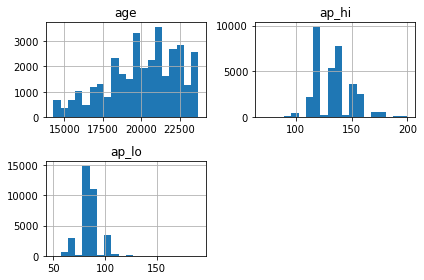

In [29]:
data = data[(data["ap_lo"] >= 50) & (data["ap_lo"] <= 200)] #ограничение по нижнему давлению от 40 до 200
data[data["cardio"] == 1][["age", "ap_hi", "ap_lo"]].hist(bins=20)
plt.tight_layout()

In [7]:
#матрица неточностей
from sklearn.metrics import confusion_matrix



import itertools
class_names = ["Здоров", "Болен"]
def plot_confusion_matrix(cm, classes, normalize=False, title='Матрица неточностей', cmap=plt.cm.Blues):    
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)
    fmt = '.4f' if normalize else 'd'
    thresh = cm.min() + (cm.max() - cm.min()) * 2 / 3.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    plt.ylabel('Истина')
    plt.xlabel('Предсказание')
    plt.tight_layout()

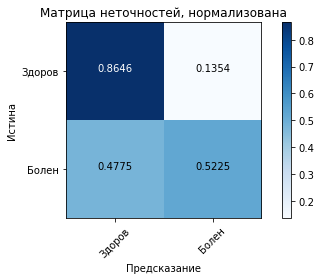

In [31]:
cnf_matrix = confusion_matrix(target, predict)
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=class_names, normalize=True,                      
                      title='Матрица неточностей, нормализована')
plt.show()

**Комментарии:** Значение точности полученное в классе = 0,62, в домашней работе = 0,69. Предположение: разнича может быть объяснена подготовкой данных. В домашней работе ограничение нижнего давления - 50, а на лекции - 40.

**2. Написать свой наивный байесовский классификатор для категориальных полей cholesterol, gluc. Привести матрицу неточностей и сравнить со значениями из задачи 1 (нельзя использовать готовое решение из sklearn) (не обязательно)**

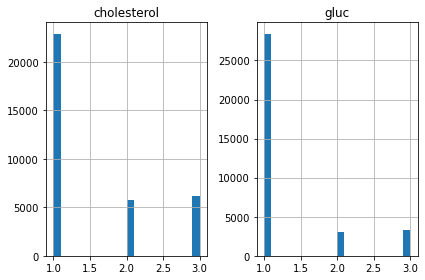

In [3]:
data = df[(df["ap_hi"] >= 50) & (df["ap_hi"] <= 200)]
data[data["cardio"] == 1][["cholesterol", "gluc"]].hist(bins=20)
plt.tight_layout()

In [18]:
data['cholesterol'].value_counts() / data.shape[0]

1    0.748451
2    0.136218
3    0.115332
Name: cholesterol, dtype: float64

In [19]:
data['gluc'].value_counts() / data.shape[0]

1    0.849725
3    0.076185
2    0.074091
Name: gluc, dtype: float64

In [4]:
#дополнительные данные. Показатели для формулы Байеса конкретно для случая с двумя переменными (глюкоза, холестерол)
p_chol_cardio1 = data[data["cardio"] == 1]['cholesterol'].value_counts()/len(data[data["cardio"] == 1]) #вероятность холестереола при наличии болезней
p_chol_cardio0 = data[data["cardio"] == 0]['cholesterol'].value_counts()/len(data[data["cardio"] == 0])#вероятность холестерола при отсутсвии болезней
p_gluc_cardio1 = data[data["cardio"] == 1]['gluc'].value_counts()/len(data[data["cardio"] == 1])  #вероятность глюкозы при наличии болезней
p_gluc_cardio0 = data[data["cardio"] == 0]['gluc'].value_counts()/len(data[data["cardio"] == 0])# вероятность глюкозы при отсутствии болезней 
p_cardio = data["cardio"].value_counts()/data.shape[0] #вероятность иметь\не иметь болезни
p_chol = data['cholesterol'].value_counts() / data.shape[0] #вероятность иметь холестерол
p_gluc = data['gluc'].value_counts() / data.shape[0] #вероятность иметь глюкозу какого-то типа

In [5]:
#классификатор
predict_category = []
predict_category_proba = []
for i in range(0, len(data)): # для каждой строки в датасете
    chol = int(data.iloc[i]['cholesterol']) # смотрим значение холестерола
    gluc = int(data.iloc[i]['gluc']) #смотрим значение глюкозы
    p_cardio1 = (p_chol_cardio1[chol]*p_gluc_cardio1[gluc]*p_cardio[1])/(p_chol[chol]*p_gluc[gluc]) #считаем вероятности болеть и не болеть по формуле байеса
    p_cardio0 = (p_chol_cardio0[chol]*p_gluc_cardio0[gluc]*p_cardio[0])/(p_chol[chol]*p_gluc[gluc])
    predict_category_proba.append((p_cardio0,  p_cardio1)) #сохраняем значения вероятностей
    if p_cardio1 > p_cardio0: res = 1 # если вероятность болеть выше чем не болеть то сохраняем 1 и 0 если наоборот
    else: res = 0
    predict_category.append(res)


In [9]:
target = data["cardio"]

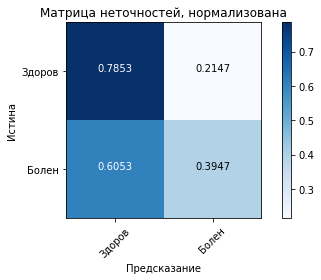

In [10]:
#матрица неточностей
cnf_matrix = confusion_matrix(target, predict_category)
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=class_names, normalize=True,                      
                      title='Матрица неточностей, нормализована')
plt.show()

**Комментарии:** Ваши комментарии здесь.

**3. Построить наивный байесовский классификатор для бинарных полей gender, smoke, alco, active. Привести матрицу неточностей и сравнить с предыдущими значениями.**

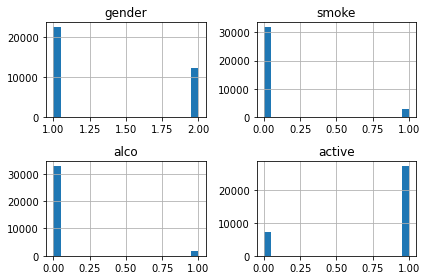

In [68]:
data[data["cardio"] == 1][["gender", "smoke", "alco","active"]].hist(bins=20)
plt.tight_layout()

In [55]:
# Your code here

from sklearn.naive_bayes import BernoulliNB
bnb = BernoulliNB()

train_boolean = data[["gender", "smoke", "alco","active"]]
target = data["cardio"]

model_boolean = bnb.fit(train_boolean, target)
predict_boolean = model.predict(train_boolean)
print(data.shape[0],
     (target == predict).sum() / data.shape[0])

predict_boolean

69712 0.6937686481523985


array([0, 0, 1, ..., 1, 1, 0], dtype=int64)

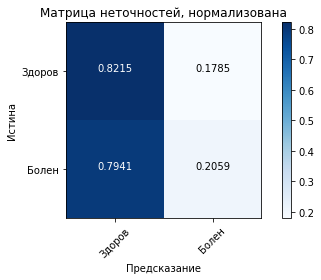

In [8]:
cnf_matrix = confusion_matrix(target, predict)
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=class_names, normalize=True,                      
                      title='Матрица неточностей, нормализована')
plt.show()

**Комментарии:** Классификатор невысокого качества. Слишком много людей относит к здоровым при наличии болезни.

**4. К этому моменту у вас есть три независимых классификатора: по количественным полям, категориальным и бинарным. Придумать, как их объединить в один единый классификатор, который учитывает все эти поля. Привести матрицу неточностей для него и сравнить с предыдущими значениями. Попытаться объяснить разницу.**

In [58]:
# так как мы считаем все действия независимыми то P(AB) = P(A)*P(B), мы можем перемножить показатели вероятностей от счетных, бинарных и категориальных величин
predict_count_proba = model_count.predict_proba(train_count)
predict_boolean_proba = model_boolean.predict_proba(train_boolean)

predict_mixed = []
for i in range(0, len(data)):
    p_cardio1 = predict_count_proba[i][1]*predict_boolean_proba[i][1]*predict_category_proba[i][1]
    p_cardio0 = predict_count_proba[i][0]*predict_boolean_proba[i][0]*predict_category_proba[i][0]
    if p_cardio1 > p_cardio0: res = 1 #аналогично заданию 2 сравниваем вероятность болеть и не болеть
    else: res = 0
    predict_mixed.append(res)
predict_mixed

[0,
 1,
 1,
 1,
 0,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 1,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 0,
 1,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 1,
 0,
 0,
 1,
 0,


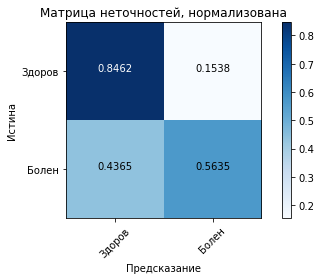

In [59]:
cnf_matrix = confusion_matrix(target, predict_mixed)
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=class_names, normalize=True,                      
                      title='Матрица неточностей, нормализована')
plt.show()

**Комментарии:** 

**5. (Не обязательно) Теперь мы умеем делать классификацию в рамках наивного предположения об независимости всех признаков. Сейчас же нужно попробовать учесть взаимосвязь между признаками через условные вероятности. Построить классификатор с учетом такой связи. Сравнить результат с ранее полученными значениями.**

In [3]:
# A lot of code here

**Комментарии:** Ваши комментарии здесь.